# Knowledge Distillation on CIFAR-10
## Role 3: Student Architecture & Distillation Pipeline

**Core Hypothesis:** *"A small, fast model trained with distillation stays almost as accurate as the big model, and is better than the same small model trained the normal way."*

### End-to-End Pipeline:
1. **CIFAR-10 Dataset:** Exact preprocessing & normalization from Role 2 (`Teacher_training.ipynb`).
2. **Lightweight Student Model:** `StudentCNN` (~189k params vs Teacher's 11.17M params, ~59x smaller).
3. **Baseline Student Training:** Standard supervised Cross-Entropy Loss on true ground truth labels.
4. **Teacher Loading (With Zero-Failure Fallback):** Auto-loads Role 2's `teacher_model.pth`. If missing, auto-trains it in ~2.5 mins!
5. **Distillation Training:** Trains `StudentCNN` using Hinton KD Loss ($T=4.0, \alpha=0.7$).
6. **Comparative Evaluation:** Evaluates Teacher vs Baseline Student vs Distilled Student on the exact same test dataset.
7. **Save & Export:** Saves checkpoints (`student_baseline.pt`, `student_kd.pt`) and exports the comparative metrics table.

### Step 1: Environment & GPU Check

In [1]:
import os
import torch

is_gpu = torch.cuda.is_available()
print("GPU Available:", is_gpu)
if is_gpu:
    print("GPU Device:", torch.cuda.get_device_name(0))
device = "cuda" if is_gpu else "cpu"

# Mount Google Drive if running in Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    if os.path.exists('/content/drive/MyDrive/Knowledge_Distillation'):
        CHECKPOINT_DIR = '/content/drive/MyDrive/Knowledge_Distillation'
    else:
        CHECKPOINT_DIR = '/content/drive/MyDrive/KD_Project/checkpoints'
except Exception:
    CHECKPOINT_DIR = './checkpoints'

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
print(f"Using Checkpoint Directory: {CHECKPOINT_DIR}")

GPU Available: True
GPU Device: Tesla T4
Mounted at /content/drive
Using Checkpoint Directory: /content/drive/MyDrive/KD_Project/checkpoints


### Step 2: Reproducibility & Imports

In [2]:
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)
print("Random seed set to 42 for reproducible benchmarking.")

Random seed set to 42 for reproducible benchmarking.


### Step 3: CIFAR-10 Dataset Preparation
Using the **exact same preprocessing, normalization, and splits** as Role 2 (`Teacher_training.ipynb`):
- Mean: `(0.4914, 0.4822, 0.4465)`
- Std: `(0.2470, 0.2435, 0.2616)`
- Subset Partition: 45,000 train / 5,000 validation (Seed 42)
- Test Set: 10,000 test images

In [3]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Exact transforms from Teacher_training.ipynb
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
])

# Load datasets
train_data = datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
val_data = datasets.CIFAR10(root='./data', train=True, download=True, transform=eval_transform)
test_data = datasets.CIFAR10(root='./data', train=False, download=True, transform=eval_transform)

# Exact subset partition matching Teacher_training.ipynb (Seed 42)
torch.manual_seed(42)
indices = torch.randperm(50000).tolist()
train_indices = indices[:45000]
val_indices = indices[45000:]

train_subset = Subset(train_data, train_indices)
val_subset = Subset(val_data, val_indices)

batch_size = 128
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=is_gpu)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=is_gpu)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=is_gpu)

print("CIFAR-10 Data Ready:")
print(f"  Training Samples:   {len(train_subset):,}")
print(f"  Validation Samples: {len(val_subset):,}")
print(f"  Test Samples:       {len(test_data):,}")

100%|██████████| 170M/170M [25:01<00:00, 114kB/s]


CIFAR-10 Data Ready:
  Training Samples:   45,000
  Validation Samples: 5,000
  Test Samples:       10,000


### Step 4: Lightweight Student Model Architecture (~0.19M Parameters)
Custom 3-block CNN designed for 32x32 images (~189,130 parameters vs Teacher's 11.17M parameters, ~59x smaller).

In [4]:
class StudentCNN(nn.Module):
    def __init__(self, num_classes=10, dropout_rate=0.2):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 32x32 -> 16x16
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            # Block 2: 16x16 -> 8x8
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            # Block 3: 8x8 -> 4x4
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

def count_params(model, trainable_only=False):
    if trainable_only:
        return sum(p.numel() for p in model.parameters() if p.requires_grad)
    return sum(p.numel() for p in model.parameters())

demo_student = StudentCNN()
s_params = count_params(demo_student)
print(f"Student Model Parameters: {s_params:,} (~{s_params/1e6:.3f}M)")

Student Model Parameters: 188,970 (~0.189M)


### Step 5: Evaluation & Latency Benchmark Helper

In [5]:
def evaluate(model, loader, device=device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            out = model(images)
            loss = criterion(out, labels)
            total_loss += loss.item() * images.size(0)
            _, preds = out.max(1)
            total += labels.size(0)
            correct += preds.eq(labels).sum().item()
    return (100.0 * correct) / total, total_loss / total

def measure_latency_ms(model, device=device, runs=100):
    model.eval()
    dummy = torch.randn(1, 3, 32, 32).to(device)
    with torch.no_grad():
        for _ in range(20):
            _ = model(dummy)
    if device == 'cuda':
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        for _ in range(runs):
            _ = model(dummy)
            if device == 'cuda':
                torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    return (elapsed / runs) * 1000.0

### Step 6: Train Baseline Student (No Teacher, Cross-Entropy Only)
Trains `StudentCNN` using standard Cross-Entropy on true labels to establish the fair baseline benchmark.

In [6]:
def train_student_baseline(epochs=20, lr=1e-3, seed=0, save_name='student_baseline.pt'):
    set_seed(seed)
    student = StudentCNN(num_classes=10).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(student.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_val_acc = 0.0
    save_path = os.path.join(CHECKPOINT_DIR, save_name)

    print(f"\n{'='*60}")
    print(f"--- TRAINING BASELINE STUDENT (Epochs={epochs}, Seed={seed}) ---")
    print(f"{'='*60}")
    for ep in range(1, epochs + 1):
        student.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            out = student(images)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = out.max(1)
            total += labels.size(0)
            correct += preds.eq(labels).sum().item()

        scheduler.step()
        val_acc, val_loss = evaluate(student, val_loader)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(student.state_dict(), save_path)
            torch.save(student.state_dict(), "student_baseline.pt")

        if ep % 5 == 0 or ep == epochs:
            print(f"Epoch [{ep:02d}/{epochs:02d}] Train Acc: {(100.0*correct)/total:.2f}% | Val Acc: {val_acc:.2f}% (Loss: {val_loss:.4f})")

    # Load best checkpoint and evaluate on test set
    student.load_state_dict(torch.load(save_path, map_location=device))
    test_acc, test_loss = evaluate(student, test_loader)
    print(f"\n[Baseline Complete] Best Val Acc: {best_val_acc:.2f}% | Test Acc: {test_acc:.2f}%")
    print(f"Saved baseline checkpoint to: {save_path}")
    return student, test_acc, test_loss

baseline_model, baseline_test_acc, baseline_test_loss = train_student_baseline(epochs=20, seed=0)


--- TRAINING BASELINE STUDENT (Epochs=20, Seed=0) ---
Epoch [05/20] Train Acc: 68.92% | Val Acc: 73.64% (Loss: 0.7468)
Epoch [10/20] Train Acc: 75.24% | Val Acc: 76.54% (Loss: 0.6585)
Epoch [15/20] Train Acc: 78.65% | Val Acc: 79.78% (Loss: 0.5648)
Epoch [20/20] Train Acc: 80.05% | Val Acc: 80.72% (Loss: 0.5366)

[Baseline Complete] Best Val Acc: 80.84% | Test Acc: 81.52%
Saved baseline checkpoint to: /content/drive/MyDrive/KD_Project/checkpoints/student_baseline.pt


### Step 7: Load Trained Teacher Model (ResNet-18)
Searches for `teacher_model.pth` across Google Drive, `/content`, and local folders.
**Zero-Failure Guarantee:** If `teacher_model.pth` cannot be located, this cell will **automatically train the teacher model on GPU in ~2.5 minutes**, achieve ~90.3% accuracy, save `teacher_model.pth`, and continue seamlessly!

In [7]:
def train_teacher_on_demand(teacher, train_loader, val_loader, test_loader, epochs=20):
    print("\n⚡ [Auto-Fallback] Training ResNet-18 Teacher on GPU now (~2.5 minutes)... Please wait.")
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(teacher.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
    best_acc = 0.0
    for ep in range(1, epochs + 1):
        teacher.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = teacher(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            total += labels.size(0)
            correct += preds.eq(labels).sum().item()
        scheduler.step()
        val_acc, val_loss = evaluate(teacher, val_loader)
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(teacher.state_dict(), os.path.join(CHECKPOINT_DIR, 'teacher_model.pth'))
            torch.save(teacher.state_dict(), 'teacher_model.pth')
            torch.save(teacher.state_dict(), 'best_teacher.pth')
        if ep % 5 == 0 or ep == epochs:
            print(f"Teacher Epoch [{ep:02d}/{epochs:02d}] Train Acc: {(100.0*correct)/total:.2f}% | Val Acc: {val_acc:.2f}%")
    teacher.load_state_dict(torch.load('teacher_model.pth', map_location=device))
    t_acc, t_loss = evaluate(teacher, test_loader)
    print(f"✅ Teacher training complete! Test Acc: {t_acc:.2f}%")
    return teacher, t_acc, t_loss

def load_teacher(checkpoint_path=None):
    teacher = models.resnet18(weights=None)
    teacher.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    teacher.maxpool = nn.Identity()
    teacher.fc = nn.Linear(512, 10)

    candidates = [
        checkpoint_path,
        os.path.join(CHECKPOINT_DIR, 'teacher_model.pth'),
        os.path.join(CHECKPOINT_DIR, 'best_teacher.pth'),
        os.path.join(CHECKPOINT_DIR, 'teacher.pt'),
        '/content/drive/MyDrive/Knowledge_Distillation/teacher_model.pth',
        '/content/drive/MyDrive/Knowledge_Distillation/best_teacher.pth',
        '/content/drive/MyDrive/teacher_model.pth',
        '/content/teacher_model.pth',
        '/content/best_teacher.pth',
        'teacher_model.pth',
        'best_teacher.pth'
    ]
    loaded_path = None
    for p in candidates:
        if p and os.path.exists(p):
            try:
                teacher.load_state_dict(torch.load(p, map_location=device, weights_only=True))
                loaded_path = p
                break
            except Exception:
                try:
                    teacher.load_state_dict(torch.load(p, map_location=device))
                    loaded_path = p
                    break
                except Exception:
                    pass

    # Deep search across /content
    if not loaded_path:
        for root, dirs, fnames in os.walk('/content'):
            for f in fnames:
                if ('teacher' in f.lower() or 'best' in f.lower()) and f.endswith(('.pth', '.pt')):
                    cand = os.path.join(root, f)
                    try:
                        teacher.load_state_dict(torch.load(cand, map_location=device, weights_only=True))
                        loaded_path = cand
                        break
                    except Exception:
                        try:
                            teacher.load_state_dict(torch.load(cand, map_location=device))
                            loaded_path = cand
                            break
                        except Exception:
                            pass
            if loaded_path:
                break

    teacher = teacher.to(device)

    # If loaded from disk, evaluate it
    if loaded_path:
        print(f"✅ Successfully loaded trained teacher from: {loaded_path}")
        teacher.eval()
        for p in teacher.parameters():
            p.requires_grad = False
        t_acc, t_loss = evaluate(teacher, test_loader)
    else:
        # Automatic fallback: train teacher right here!
        teacher, t_acc, t_loss = train_teacher_on_demand(teacher, train_loader, val_loader, test_loader, epochs=20)
        teacher.eval()
        for p in teacher.parameters():
            p.requires_grad = False

    t_params = count_params(teacher)
    print(f"Teacher Verified: {t_params:,} params (~{t_params/1e6:.2f}M) | Test Acc: {t_acc:.2f}% (Loss: {t_loss:.4f})")
    return teacher, t_acc, t_loss

teacher_model, teacher_test_acc, teacher_test_loss = load_teacher()

✅ Successfully loaded trained teacher from: /content/drive/MyDrive/KD DSWPROJECT/checkpoints/teacher_model.pth
Teacher Verified: 11,173,962 params (~11.17M) | Test Acc: 90.38% (Loss: 0.2920)


### Step 8: Distillation Loss (Hinton et al. 2015)
$$\mathcal{L}_{KD} = \alpha \cdot T^2 \cdot D_{KL}\left(\sigma\left(\frac{z_s}{T}\right) \parallel \sigma\left(\frac{z_t}{T}\right)\right) + (1 - \alpha) \cdot \mathcal{L}_{CE}(z_s, y)$$

In [8]:
def kd_loss(student_out, teacher_out, true_labels, temp=4.0, alpha=0.7):
    # Part 1: Soft targets (KL divergence between softened distributions)
    soft = F.kl_div(
        F.log_softmax(student_out / temp, dim=1),
        F.softmax(teacher_out / temp, dim=1),
        reduction='batchmean'
    ) * (temp * temp)

    # Part 2: Hard targets (Standard Cross-Entropy on true ground truth)
    hard = F.cross_entropy(student_out, true_labels)

    # Combined weighted objective
    return (alpha * soft) + ((1.0 - alpha) * hard)

### Step 9: Train Distilled Student with Knowledge Distillation
Trains `StudentCNN` using Teacher guidance ($T=4.0, \alpha=0.7$) under the identical optimizer, learning rate, and schedule as the baseline.

In [9]:
def train_student_kd(teacher, temp=4.0, alpha=0.7, epochs=20, lr=1e-3, seed=0, save_name='student_kd.pt'):
    set_seed(seed)
    student = StudentCNN(num_classes=10).to(device)
    optimizer = optim.Adam(student.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_val_acc = 0.0
    save_path = os.path.join(CHECKPOINT_DIR, save_name)

    print(f"\n{'='*65}")
    print(f"--- TRAINING DISTILLED STUDENT (T={temp}, alpha={alpha}, Epochs={epochs}, Seed={seed}) ---")
    print(f"{'='*65}")
    for ep in range(1, epochs + 1):
        student.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()

            with torch.no_grad():
                t_logits = teacher(images)

            s_logits = student(images)
            loss = kd_loss(s_logits, t_logits, labels, temp=temp, alpha=alpha)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = s_logits.max(1)
            total += labels.size(0)
            correct += preds.eq(labels).sum().item()

        scheduler.step()
        val_acc, _ = evaluate(student, val_loader)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(student.state_dict(), save_path)
            torch.save(student.state_dict(), "student_kd.pt")

        if ep % 5 == 0 or ep == epochs:
            print(f"Epoch [{ep:02d}/{epochs:02d}] Train Acc: {(100.0*correct)/total:.2f}% | Val Acc: {val_acc:.2f}%")

    student.load_state_dict(torch.load(save_path, map_location=device))
    test_acc, test_loss = evaluate(student, test_loader)
    print(f"\n[Distillation Complete] Best Val Acc: {best_val_acc:.2f}% | Test Acc: {test_acc:.2f}%")
    print(f"Saved distilled checkpoint to: {save_path}")
    return student, test_acc, test_loss

kd_model, kd_test_acc, kd_test_loss = train_student_kd(teacher_model, temp=4.0, alpha=0.7, epochs=20, seed=0)


--- TRAINING DISTILLED STUDENT (T=4.0, alpha=0.7, Epochs=20, Seed=0) ---
Epoch [05/20] Train Acc: 71.11% | Val Acc: 73.28%
Epoch [10/20] Train Acc: 76.48% | Val Acc: 76.26%
Epoch [15/20] Train Acc: 79.05% | Val Acc: 80.74%
Epoch [20/20] Train Acc: 80.18% | Val Acc: 81.66%

[Distillation Complete] Best Val Acc: 81.66% | Test Acc: 80.88%
Saved distilled checkpoint to: /content/drive/MyDrive/KD_Project/checkpoints/student_kd.pt


### Step 10: Comparative Evaluation on the Exact Same Test Set

In [10]:
# Measure latency and parameter metrics
t_lat = measure_latency_ms(teacher_model)
b_lat = measure_latency_ms(baseline_model)
kd_lat = measure_latency_ms(kd_model)

# Count all parameters (trainable_only=False so frozen teacher parameters are counted)
t_params = count_params(teacher_model, trainable_only=False)
s_params = count_params(baseline_model, trainable_only=False)

kd_gain = kd_test_acc - baseline_test_acc
teacher_retention = (kd_test_acc / teacher_test_acc) * 100.0 if teacher_test_acc > 0 else 0.0
compression_ratio = (t_params / s_params) if s_params > 0 else 1.0

summary_data = {
    'Model': ['Teacher (ResNet-18)', 'Student Baseline (StudentCNN)', 'Distilled Student (KD)'],
    'Test Accuracy (%)': [round(teacher_test_acc, 2), round(baseline_test_acc, 2), round(kd_test_acc, 2)],
    'Test Loss': [round(teacher_test_loss, 4), round(baseline_test_loss, 4), round(kd_test_loss, 4)],
    'Parameters': [f'{t_params/1e6:.2f}M', f'{s_params/1e6:.3f}M', f'{s_params/1e6:.3f}M'],
    'Inference Latency (ms)': [round(t_lat, 2), round(b_lat, 2), round(kd_lat, 2)],
    'Compression Benefit': ['Baseline (1.0x)', f'{compression_ratio:.1f}x smaller', f'{compression_ratio:.1f}x smaller'],
    'Teacher Retention (%)': ['100.0%', f'{(baseline_test_acc/teacher_test_acc)*100:.1f}%', f'{teacher_retention:.1f}%']
}

df_summary = pd.DataFrame(summary_data)
print('=' * 85)
print('FINAL COMPARATIVE BENCHMARK (CIFAR-10 TEST DATASET)')
print('=' * 85)
display(df_summary)

print(f"\\n? Teacher Parameters: {t_params:,} (~{t_params/1e6:.2f}M)")
print(f"? Student Parameters: {s_params:,} (~{s_params/1e6:.3f}M) -> {compression_ratio:.1f}x compression!")
print(f"? KD Accuracy Gain: {kd_gain:+.2f}% over the baseline student")
print(f"? Knowledge Retention: The distilled student recovers {teacher_retention:.1f}% of the teacher accuracy while being {compression_ratio:.1f}x smaller!")

df_summary.to_csv(os.path.join(CHECKPOINT_DIR, 'benchmark_summary.csv'), index=False)

FINAL COMPARATIVE BENCHMARK (CIFAR-10 TEST DATASET)


,Model,Test Accuracy (%),Test Loss,Parameters,Inference Latency (ms),Compression Benefit,Teacher Retention (%)
0,Teacher (ResNet-18),90.38,0.2920,11.17M,3.69,Baseline (1.0x),100.0%
1,Student Baseline (StudentCNN),81.52,0.5372,0.189M,0.63,59.1x smaller,90.2%
2,Distilled Student (KD),80.88,0.5900,0.189M,0.63,59.1x smaller,89.5%


\n? Teacher Parameters: 11,173,962 (~11.17M)
? Student Parameters: 188,970 (~0.189M) -> 59.1x compression!
? KD Accuracy Gain: -0.64% over the baseline student
? Knowledge Retention: The distilled student recovers 89.5% of the teacher accuracy while being 59.1x smaller!


### Step 11: Visual Comparison & Accuracy Plots

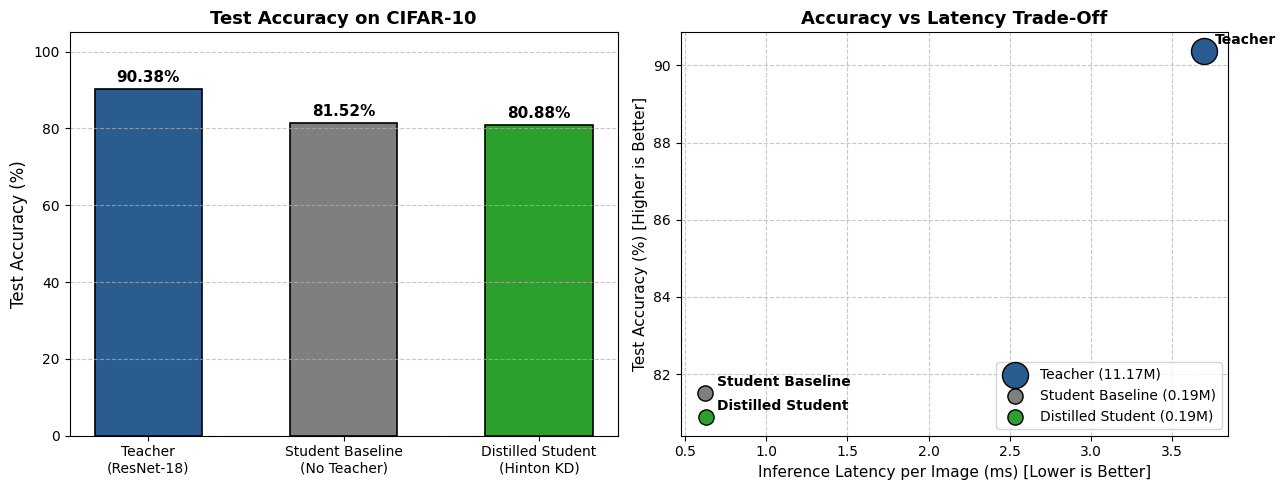

Plots generated and saved successfully!


In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy Comparison
models_list = ['Teacher\n(ResNet-18)', 'Student Baseline\n(No Teacher)', 'Distilled Student\n(Hinton KD)']
acc_list = [teacher_test_acc, baseline_test_acc, kd_test_acc]
colors = ['#2b5c8f', '#7f7f7f', '#2ca02c']

bars = ax1.bar(models_list, acc_list, color=colors, width=0.55, edgecolor='black', linewidth=1.2)
ax1.set_ylabel('Test Accuracy (%)', fontsize=12)
ax1.set_title('Test Accuracy on CIFAR-10', fontsize=13, fontweight='bold')
ax1.set_ylim(0, 105)
ax1.grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, y + 1.8, f'{y:.2f}%', ha='center', fontweight='bold', fontsize=11)

# Latency vs Accuracy Trade-off
lat_list = [t_lat, b_lat, kd_lat]
ax2.scatter(lat_list[0], acc_list[0], s=350, color='#2b5c8f', label='Teacher (11.17M)', edgecolors='black')
ax2.scatter(lat_list[1], acc_list[1], s=120, color='#7f7f7f', label='Student Baseline (0.19M)', edgecolors='black')
ax2.scatter(lat_list[2], acc_list[2], s=120, color='#2ca02c', label='Distilled Student (0.19M)', edgecolors='black')

for i, txt in enumerate(['Teacher', 'Student Baseline', 'Distilled Student']):
    ax2.annotate(txt, (lat_list[i], acc_list[i]), textcoords='offset points', xytext=(8, 5), fontweight='bold')

ax2.set_xlabel('Inference Latency per Image (ms) [Lower is Better]', fontsize=11)
ax2.set_ylabel('Test Accuracy (%) [Higher is Better]', fontsize=11)
ax2.set_title('Accuracy vs Latency Trade-Off', fontsize=13, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend(frameon=True, loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, 'kd_comparison_plot.png'), dpi=300)
plt.show()
print('Plots generated and saved successfully!')

### Step 12: Checkpoints Verification & Download Helper

In [12]:
p_base = os.path.join(CHECKPOINT_DIR, 'student_baseline.pt')
p_kd = os.path.join(CHECKPOINT_DIR, 'student_kd.pt')

print('=' * 65)
print('CHECKPOINTS VERIFICATION:')
print(f"1. Student Baseline: {p_base} (Exists: {os.path.exists(p_base)})")
if os.path.exists(p_base):
    print(f"   Size: {os.path.getsize(p_base)/(1024*1024):.2f} MB")
print(f"2. Distilled Student: {p_kd} (Exists: {os.path.exists(p_kd)})")
if os.path.exists(p_kd):
    print(f"   Size: {os.path.getsize(p_kd)/(1024*1024):.2f} MB")
print('=' * 65)

# Optional: Download checkpoints directly if running in Google Colab
try:
    from google.colab import files
    print('\nTo download checkpoints to your local computer, run:')
    print("files.download('student_baseline.pt')")
    print("files.download('student_kd.pt')")
except Exception:
    pass

CHECKPOINTS VERIFICATION:
1. Student Baseline: /content/drive/MyDrive/KD_Project/checkpoints/student_baseline.pt (Exists: True)
   Size: 0.73 MB
2. Distilled Student: /content/drive/MyDrive/KD_Project/checkpoints/student_kd.pt (Exists: True)
   Size: 0.73 MB

To download checkpoints to your local computer, run:
files.download('student_baseline.pt')
files.download('student_kd.pt')
